# robustness demo
Is a backtest's edge real, or an artefact of how we found it? Five probes:
**PBO** (was the best config picked from noise?), **walk-forward vs in-sample** (did the model memorise its training data?), **perturbations** (price noise, a day's delay, nearby parameters), **regimes**, and **calibration**.

Everything runs on the training window; the hold-out appears once, in the report's last row. Synthetic data: illustrations of the method only.

In [1]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

from quantskills.data import synthetic_prices, to_wide
from quantskills.eval import sharpe_ratio
from quantskills.features import feature_panel, label_panel
from quantskills.models import dropna_xy, oof_predictions
from quantskills.robustness import (
    calibration_summary,
    pbo_cscv,
    plot_decay,
    plot_pbo,
    plot_reliability,
    plot_surface,
    reliability_table,
    robustness_report,
)
from quantskills.robustness.perturb import insample_backtest, walk_forward_backtest
from quantskills.strategies import GBMLongShort
from quantskills.utils import holdout_date

prices = synthetic_prices(seed=0, n_pairs=3, garch_index=True)
dates = prices.index.get_level_values("date")
train_end = holdout_date(dates, 0.3)
train = prices[dates <= train_end]
print(f"train <= {train_end.date()}")

train <= 2018-05-21


## 1. PBO: picking the best of N noise series
CSCV cuts history into 16 blocks and, for each of the 12,870 ways to use half as in-sample, asks where the in-sample winner ranks out of sample. With 20 pure-noise configs it lands below the median about half the time (PBO ≈ 0.5). Give one config a real edge and PBO drops to about 0.

  20 noise configs: PBO 0.45, P(IS winner loses OOS) 0.45
     one real edge: PBO 0.00, P(IS winner loses OOS) 0.00


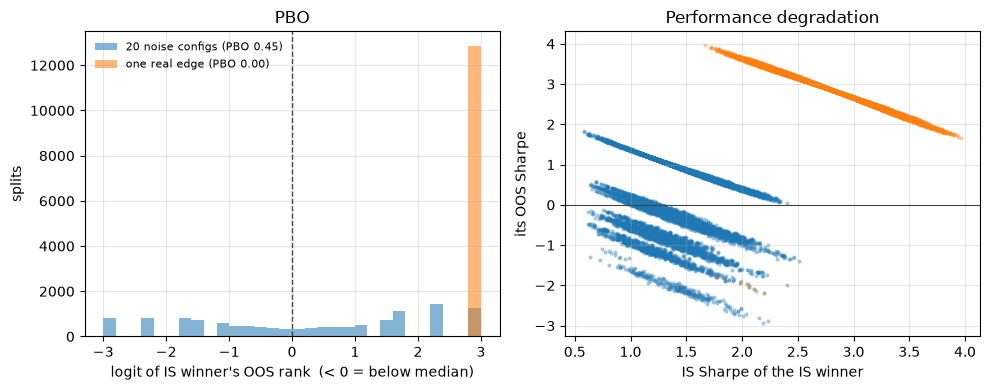

In [2]:
rng = np.random.default_rng(0)
noise = rng.normal(0, 0.01, (1000, 20))
edge = noise.copy()
edge[:, 3] += 0.002
res = {"20 noise configs": pbo_cscv(noise), "one real edge": pbo_cscv(edge)}
for k, r in res.items():
    print(f"{k:>18}: PBO {r.pbo:.2f}, P(IS winner loses OOS) {r.prob_oos_loss:.2f}")
plot_pbo(res);

## 2. In-sample checks miss memorisation
Score LightGBM on the days it was fitted to and it looks brilliant. Score it walk-forward *inside the training window* (fit on the past, trade the next block) and most of the edge disappears. No hold-out needed to see it.

In [3]:
params = {"max_rounds": 100}
ins, _ = insample_backtest(GBMLongShort(**params), train)
wf, _ = walk_forward_backtest(GBMLongShort, params, train, n_folds=4)
print(f"in-sample Sharpe   : {sharpe_ratio(ins.returns):.2f}")
print(f"walk-forward Sharpe: {sharpe_ratio(wf.returns):.2f}")

in-sample Sharpe   : 3.47
walk-forward Sharpe: 0.34


## 3. The full report: pairs (#3)
One call runs DSR, PBO over a 3x3 grid, 25 bps price noise, a 1-day delay, the sensitivity surface and regimes, then grades each check. (One noise seed here to keep the demo quick; the CLI uses two.)

In [4]:
r = robustness_report("pairs-coint", prices, train_end, noise_seeds=(0,))
print("verdict:", r.verdict.upper())
r.checks_table()[["check", "status", "value"]]

verdict: AMBER


,check,status,value
0,Deflated Sharpe,amber,"0.95 (SR 2.04 vs 0.66, N=10)"
1,PBO (CSCV),amber,"0.69, P(loss) 0.15, 9 configs"
2,Sensitivity (worst / base),green,0.62 kept (worst SR 1.27)
3,Price noise 25 bps,amber,0.68 kept (SR 1.38)
4,Trade 1 day late,green,0.93 kept (SR 1.89)
5,Worst regime Sharpe,green,1.37 (up trend)
6,Walk-forward / in-sample,green,1.09 (SR 1.87 → 2.04)
7,Hold-out / in-sample,green,1.37 (SR 1.87 → 2.56)


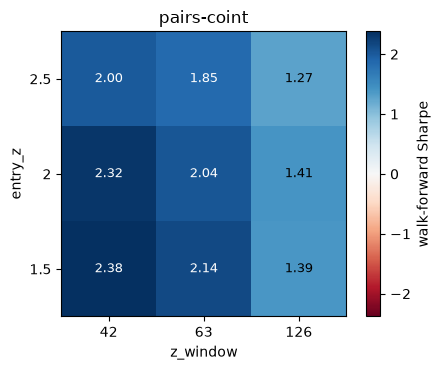

In [5]:
plot_surface(r.surface, title="pairs-coint", label="walk-forward Sharpe");

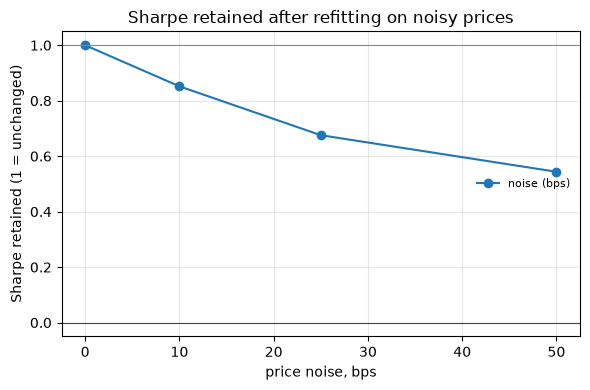

In [6]:
plot_decay(
    {"noise (bps)": r.noise_summary()["sharpe"]},
    xlabel="price noise, bps",
    title="Sharpe retained after refitting on noisy prices",
);

In [7]:
r.delay.set_index("delay").T.round(2)  # Sharpe when trading k days late

delay,0,1,2,5
sharpe,2.04,1.89,1.12,0.97


Regimes are labelled with past data only (trailing vol vs its expanding median; index vs its 200-day average) and lagged a day before matching returns.

In [8]:
r.regimes.round(2)

days  share  ann_return  ann_vol  sharpe  max_drawdown
kind  regime                                                            
vol   high vol      89   0.28        0.05     0.03    1.58         -0.02
      low vol      228   0.72        0.07     0.03    2.21         -0.02
trend down trend   120   0.38        0.11     0.03    3.10         -0.01
      up trend     197   0.62        0.04     0.03    1.37         -0.02

## 4. Calibration
A logistic model for P(stock beats the median over 21 days), with probabilities from walk-forward models only. On this panel it is no better than always saying 50% (Brier skill ≈ 0): its most confident bin says 59% and comes true about 49% of the time. Making it overconfident (same ranking) makes the ECE about five times worse.

,logistic,overconfident x4
brier,0.2509,0.2808
brier_climatology,0.2498,0.2498
brier_skill,-0.0044,-0.1238
ece,0.0320,0.1508


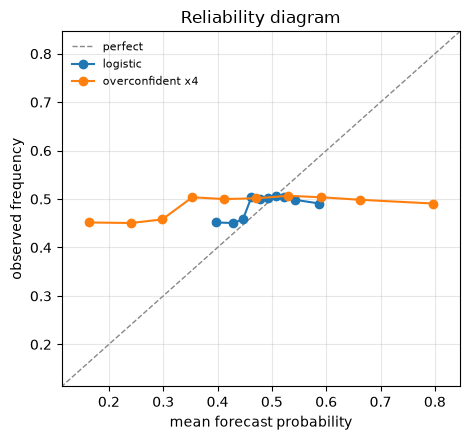

In [9]:
close = to_wide(train, "close")
X, y = dropna_xy(feature_panel(close), label_panel(close, 21, "up"))
p = oof_predictions(
    lambda: LogisticRegression(C=0.01, max_iter=1000),
    X,
    y,
    predict=lambda m, x: m.predict_proba(x)[:, 1],
)
yy = y.reindex(p.index)
sharp = 1 / (1 + np.exp(-4 * np.log(p / (1 - p))))
summary = pd.DataFrame(
    {"logistic": calibration_summary(p, yy), "overconfident x4": calibration_summary(sharp, yy)}
)
display(summary.loc[["brier", "brier_climatology", "brier_skill", "ece"]].round(4))
plot_reliability(
    {"logistic": reliability_table(p, yy), "overconfident x4": reliability_table(sharp, yy)}
);

## Takeaways
- Read **walk-forward vs in-sample** first: it catches memorisation without the hold-out.
- **PBO** judges the *selection*; pair it with P(OOS loss), since on a plateau of good configs PBO ≈ 0.5 is harmless.
- Perturbation checks catch fragile edges. A **green** verdict is a triage flag, not proof.
- All numbers above are synthetic. See `docs/robustness.md` for the seven-strategy table.